In [ ]:
import pandas as pd

# 1. Replace 'your_file_name.csv' with the name of your uploaded file
file_path = '/content/fbref ball carrying - all.csv'

# 2. Read the file into a variable named 'df'
try:
    df = pd.read_csv(file_path)
    print("Success! Your CSV dataset is loaded into the variable 'df'.")

    # 3. Show the first 5 rows of your data
    display(df.head())
except FileNotFoundError:
    print(f"Could not find a file named '{file_path}'. Please make sure you uploaded it to the left sidebar and spelled the name correctly!")

Success! Your CSV dataset is loaded into the variable 'df'.


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Touches,Unnamed: 9,...,Carries,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Receiving,Unnamed: 29
0,Rk,Player,Nation,Pos,Squad,Age,Born,90s,Touches,Def Pen,...,Carries,TotDist,PrgDist,PrgC,1/3,CPA,Mis,Dis,Rec,PrgR
1,1,Patrick van Aanholt,nl NED,DF,Crystal Palace,26,1990,24.3,1435,90,...,717,3714,1966,46,33,7,37,18,711,86
2,2,Rolando Aarons,eng ENG,"MF,FW",Newcastle Utd,21,1995,1.5,65,0,...,37,380,127,7,3,3,4,6,39,4
3,3,Tammy Abraham,eng ENG,FW,Swansea City,19,1997,19.2,498,12,...,305,1600,555,19,16,8,50,51,393,104
4,4,Charlie Adam,sct SCO,MF,Stoke City,31,1985,4.6,342,9,...,206,960,436,6,15,2,7,5,211,9


In [ ]:
# Create a mask for rows where the first column starts with "Rk", fbref has these around every 25 rows
mask = df.iloc[:, 0].astype(str).str.startswith("Rk", na=False)

# Keep the first matching row, drop the rest
if mask.any():
    first_rk_idx = mask.idxmax()
    mask.loc[first_rk_idx] = False

df = df[~mask]
df = df.reset_index(drop=True)

df.head(105)  # check the result

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Touches,Unnamed: 9,...,Carries,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Receiving,Unnamed: 29
0,Rk,Player,Nation,Pos,Squad,Age,Born,90s,Touches,Def Pen,...,Carries,TotDist,PrgDist,PrgC,1/3,CPA,Mis,Dis,Rec,PrgR
1,1,Patrick van Aanholt,nl NED,DF,Crystal Palace,26,1990,24.3,1435,90,...,717,3714,1966,46,33,7,37,18,711,86
2,2,Rolando Aarons,eng ENG,"MF,FW",Newcastle Utd,21,1995,1.5,65,0,...,37,380,127,7,3,3,4,6,39,4
3,3,Tammy Abraham,eng ENG,FW,Swansea City,19,1997,19.2,498,12,...,305,1600,555,19,16,8,50,51,393,104
4,4,Charlie Adam,sct SCO,MF,Stoke City,31,1985,4.6,342,9,...,206,960,436,6,15,2,7,5,211,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,100,Steve Cook,eng ENG,DF,Bournemouth,26,1991,30.7,1831,261,...,704,4154,2241,15,6,1,15,7,883,9
101,101,Francis Coquelin,fr FRA,"MF,DF",Arsenal,26,1991,1.9,107,4,...,67,286,130,1,0,0,1,2,79,1
102,102,Jack Cork,eng ENG,MF,Burnley,28,1989,38,1959,91,...,966,4955,1898,39,40,2,67,44,1159,41
103,103,Thibaut Courtois,be BEL,GK,Chelsea,25,1992,35,1250,1140,...,635,4072,2260,0,0,0,1,0,615,0


In [ ]:
import pandas as pd

# 1. Upload the file in Colab first (Files sidebar → Upload),
#    or if it's already there, just load it:
df = pd.read_csv('fbref ball carrying - all.csv')

# 2. Drop all repeated "Rk" rows except the first one
mask = df.iloc[:, 0] == 'Rk'
if mask.any():
    first_idx = mask.idxmax()
    mask.loc[first_idx] = False          # keep the first Rk row

df = df[~mask].copy()

# 3. Promote that first row to real column headers
df.columns = df.iloc[0]
df = df[1:].reset_index(drop=True)

# 4. Done — check the result
print(df.shape)
df.head()

(1356, 30)


,Rk,Player,Nation,Pos,Squad,Age,Born,90s,Touches,Def Pen,...,Carries,TotDist,PrgDist,PrgC,1/3,CPA,Mis,Dis,Rec,PrgR
0,1,Patrick van Aanholt,nl NED,DF,Crystal Palace,26,1990,24.3,1435,90,...,717,3714,1966,46,33,7,37,18,711,86
1,2,Rolando Aarons,eng ENG,"MF,FW",Newcastle Utd,21,1995,1.5,65,0,...,37,380,127,7,3,3,4,6,39,4
2,3,Tammy Abraham,eng ENG,FW,Swansea City,19,1997,19.2,498,12,...,305,1600,555,19,16,8,50,51,393,104
3,4,Charlie Adam,sct SCO,MF,Stoke City,31,1985,4.6,342,9,...,206,960,436,6,15,2,7,5,211,9
4,5,Adrián,es ESP,GK,West Ham,30,1987,19,641,541,...,284,2193,1505,0,0,0,0,0,166,0


In [ ]:
# Now the first row is correctly used as headers

# Convert key columns to numbers
for col in ['90s', 'Touches', 'Carries', 'TotDist', 'PrgDist', 'PrgC', '1/3', 'CPA']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Filter: Getting rid of players that have insignificant values (a goalkeeper will have close to zero in most of these metrics)
# - At least 5 full matches (90s >= 5)
# - At least 10 progressive carries OR 800+ progressive distance
df_filtered = df[
    (df['90s'] >= 5) &
    ((df['PrgC'] >= 10) | (df['PrgDist'] >= 800))
].copy()

print(f"Players before: {len(df)}")
print(f"Players after:  {len(df_filtered)}")
print(f"Removed:        {len(df) - len(df_filtered)}")

Players before: 1356
Players after:  867
Removed:        489


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Customizing charts/graphs
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

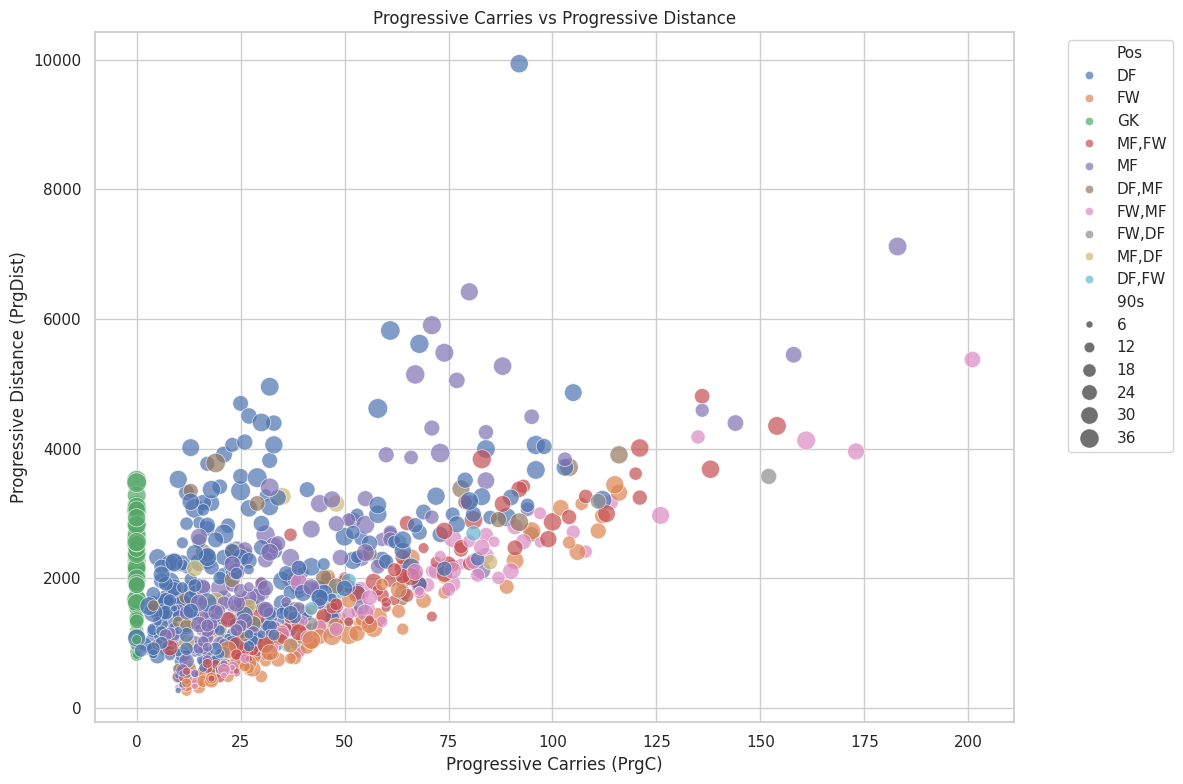

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df_filtered,
    x='PrgC',
    y='PrgDist',
    hue='Pos',
    size='90s',          # bubble size = minutes played
    sizes=(20, 200),
    alpha=0.7
)
plt.title('Progressive Carries vs Progressive Distance')
plt.xlabel('Progressive Carries (PrgC)')
plt.ylabel('Progressive Distance (PrgDist)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

fig = px.scatter(
    df_plot,
    x='PrgC',
    y='Succ',
    color='Pos',
    size='90s',
    hover_name='Player',
    title='Progressive Carries vs Successful Dribbles'
)
fig.update_layout(height=700, yaxis_title='Successful Dribbles (Succ)')
fig.show()

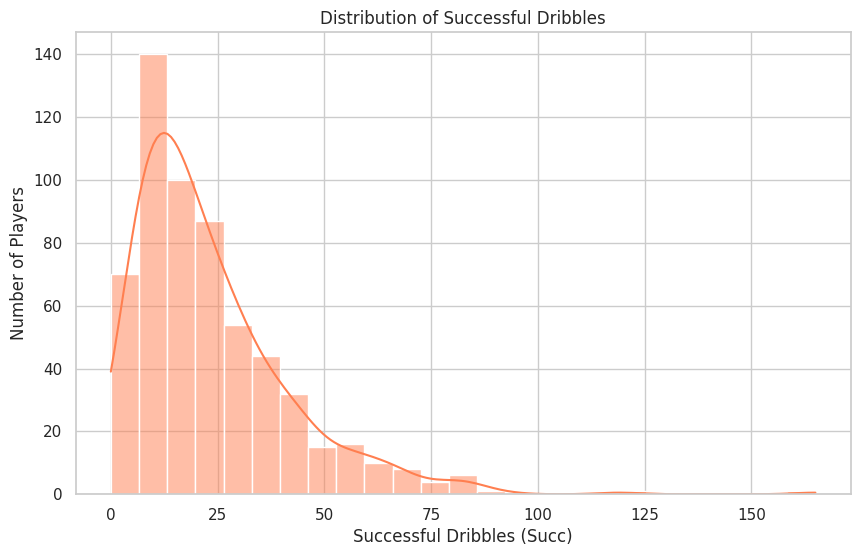

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='Succ', bins=25, color='coral', kde=True)
plt.title('Distribution of Successful Dribbles')
plt.xlabel('Successful Dribbles (Succ)')
plt.ylabel('Number of Players')
plt.show()

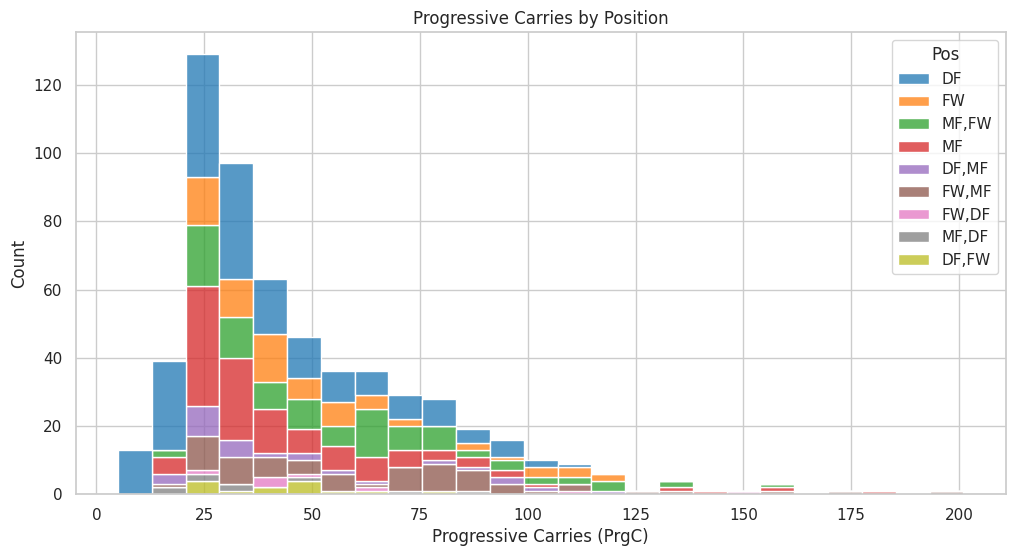

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(
    data=df_filtered,
    x='PrgC',
    hue='Pos',
    bins=25,
    multiple='stack',   # or 'layer' / 'dodge'
    palette='tab10'
)
plt.title('Progressive Carries by Position')
plt.xlabel('Progressive Carries (PrgC)')
plt.show()

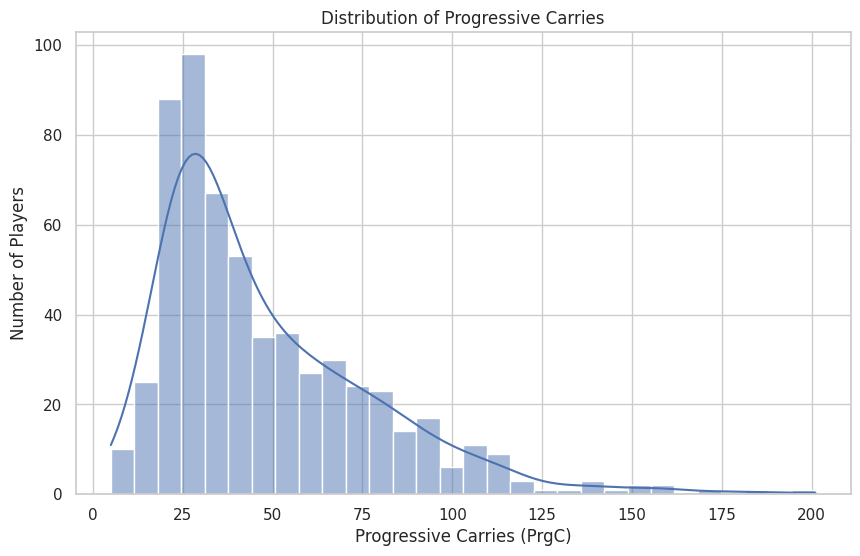

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='PrgC', bins=30, kde=True)
plt.title('Distribution of Progressive Carries')
plt.xlabel('Progressive Carries (PrgC)')
plt.ylabel('Number of Players')
plt.show()

## Summary of the Dataset and Key Observations

The cleaned dataset contains progressive ball-carrying statistics for outfield players. Key columns include:

- **PrgC**: Progressive carries (carries that move the ball significantly toward the opponent’s goal)
- **Succ**: Successful take-ons (dribbles)
- **PrgDist**: Progressive carrying distance
- **Pos**: Player position

**Key observations So Far:**
- Goalkeepers were fully removed as they recorded 0 progressive carries.
- There is a wide range in progressive carrying volume; a small group of players (primarily attacking midfielders and wingers) dominate both progressive carries and successful dribbles.
- Defenders generally show lower progressive carrying volume compared to midfielders and forwards, though full-backs can still appear as outliers.

**Link to dataset**
https://web.archive.org/web/20231211051052/https://fbref.com/en/comps/12/2017-2018/possession/2017-2018-La-Liga-Stats